# HKM

In [51]:
from sklearn.cluster import KMeans
# from sklearn.datasets import make_blobs
import sklearn.datasets as datasets
import numpy as np
import matplotlib.pyplot as plt
import time


In [52]:
# taken from https://gist.github.com/danoneata/49a807f47656fedbb389

def fvecs_read(filename, c_contiguous=True):
    """
    reads a file in the fvecs format, returning a 2D numpy array of shape (n, d)
    """
    fv = np.fromfile(filename, dtype=np.float32)
    if fv.size == 0:
        return np.zeros((0, 0))
    dim = fv.view(np.int32)[0]
    assert dim > 0
    fv = fv.reshape(-1, 1 + dim)
    if not all(fv.view(np.int32)[:, 0] == dim):
        raise IOError("Non-uniform vector sizes in " + filename)
    fv = fv[:, 1:]
    if c_contiguous:
        fv = fv.copy()
    return fv

In [53]:
# taken from https://gist.github.com/CharlesLiu7/0496773a8a21934a746e3fd496f11e0c

def ivecs_read(fname):
    a = np.fromfile(fname, dtype='int32')
    d = a[0]
    return a.reshape(-1, d + 1)[:, 1:].copy()

In [54]:
class Node:
    # centroid <array_centroid : pointer children>
    def __init__(self, centroids, childrens):
        # array di centroidi 
        self.centroids = centroids
        self.children = childrens
        
    def distances(self, x):
        """
        Compute the distances between the input vector x and the centroids of the node.
        Parameters:
            x (numpy array): The input vector.
        Returns:
            numpy array: The distances between x and the centroids of the node.
        """
        return np.linalg.norm(self.centroids - x, axis=1)
        
    def profiled_distances(self, x):
        """
        Compute the distances between the input vector x and the centroids of the node, while also measuring the time taken for the computation.
        Parameters:
            x (numpy array): The input vector.
        Returns:
            tuple: A tuple containing the distances between x and the centroids of the node, and the time taken for the computation in milliseconds.
        """
        start_time = time.perf_counter()
        dists = np.linalg.norm(self.centroids - x, axis=1)
        elapsed_ms = (time.perf_counter() - start_time)*1000.0
        return dists, elapsed_ms

class LeafNode:
    def __init__(self, mapping, local_data):
        #!! store both mapping and data so when i need to compute distances i use data while when i need to return the mapping i use mapping
        self.mappings = mapping
        self.local_data = local_data 
        # copy of the data 
    
    def distances(self, x):
        """
        Compute the distances between the input vector x and the local data points.
        Parameters:
            x (numpy array): The input vector.
        Returns:
            numpy array: The distances between x and the local data points.
        """
        return np.linalg.norm(self.local_data - x, axis=1)
        
    def profiled_distances(self, x):
        """
        Compute the distances between the input vector x and the local data points, while also measuring the time taken for the computation.
        Parameters:
            x (numpy array): The input vector.
        Returns:
            tuple: A tuple containing the distances between x and the local data points, and the time taken for the computation in milliseconds.
        """
        start_time = time.perf_counter()
        dists = np.linalg.norm(self.local_data - x, axis=1)
        elapsed_ms = (time.perf_counter() - start_time)*1000.0
        return dists, elapsed_ms


In [82]:
def hkm(D, k, L_max, N_min):
    """
    HKM algorithm for hierarchical k-means.
    Parameters:
        D: Dataset
        k: branching factor
        L_max: maximum depth level
        N_min: minimum number of points in a cluster

    Returns:
        A node representing the root of the hierarchical k-means clustering of the dataset D.
    """

    def _hkm(D_idx, l=0):

        # if the dataset is less than N_min or we have reached the maximum depth level, return the cluster
        if len(D_idx) < N_min or len(D_idx) < k or l == L_max: #! aggiunto or len(D_idx) < k per evitare di fare kmeans su un numero di punti minore di k, in questo caso è inutile fare kmeans e conviene direttamente creare una leaf
            return LeafNode(mapping=D_idx, local_data=D[D_idx]) # copy of the data , it's done automactically when we create a new array with the indexing

        # split_data = D[D_idx]
        kmeans = KMeans(n_clusters=k, random_state=42).fit(D[D_idx]) # could use variable but redundant copy
        
        childrens = []
        for i in range(k):
            childrens.append(_hkm(D_idx[kmeans.labels_ == i], l + 1)) # copia solo a leaf 

        return Node(centroids=kmeans.cluster_centers_, childrens=childrens) 
    
    return _hkm(np.arange(len(D)), l=0)

In [56]:
class SearchPerf:
    def __init__(self):
        self.centroid_iter = 0
        self.centroid_distances_time = 0.0
        self.centroid_argmin_time = 0.0
        
        self.leaf_distances_time = 0.0
        self.leaf_argmin_time = 0.0

    def total_time(self):
        return self.centroid_distances_time + self.centroid_argmin_time + self.leaf_distances_time + self.leaf_argmin_time
    
    def total_centroid_time(self):
        return self.centroid_distances_time + self.centroid_argmin_time
    
    def total_leaf_time(self):
        return self.leaf_distances_time + self.leaf_argmin_time
    
    def total_argmin_time(self):
        return self.centroid_argmin_time + self.leaf_argmin_time
    
    def total_distances_time(self):
        return self.centroid_distances_time + self.leaf_distances_time
    
    # def plots(self):
        

In [57]:
def hkm_search(node, x, D):
    """
    Search for nearest neighbor of x in the dataset D using the hierarchical k-means clustering tree T.
    Parameters:
        node: the root of the hierarchical k-means clustering tree
        x: the query point
        D: the original dataset

    Returns:
        The index of the nearest neighbor of x in the dataset D.
    """

    def _search(node):
        if isinstance(node, LeafNode):
            # pts = D[node.mappings]
            distances = np.linalg.norm(node.local_data - x, axis=1)
            closest_idx = np.argmin(distances)
            return node.mappings[closest_idx]
        else:
            closest = node.children[np.argmin(node.distances(x))]
            return _search(closest)
    
    return _search(node)

def hkm_search(node, x):
    """
    Search for nearest neighbor of x in the dataset D using the hierarchical k-means clustering tree T.
    Parameters:
        node: the root of the hierarchical k-means clustering tree
        x: the query point
        D: the original dataset

    Returns:
        The index of the nearest neighbor of x in the dataset D.
    """
    perf_obj = SearchPerf()
    def _search(node):
        if isinstance(node, LeafNode):
            # print("leaf node base", node.local_data.base)
            distances, elapsed_ms = node.profiled_distances(x)
            perf_obj.leaf_distances_time += elapsed_ms

            start_time = time.perf_counter()
            closest_idx = np.argmin(distances)
            perf_obj.leaf_argmin_time += (time.perf_counter()-start_time)*1000.0

            return node.mappings[closest_idx]
        else:
            distances, elapsed_ms = node.profiled_distances(x)
            perf_obj.centroid_distances_time += elapsed_ms
            perf_obj.centroid_iter += 1

            start_time = time.perf_counter()
            closest_cluster = np.argmin(distances)
            perf_obj.centroid_argmin_time += (time.perf_counter()-start_time)*1000.0

            closest_cluster_child = node.children[closest_cluster]
            return _search(closest_cluster_child)
    
    idx = _search(node)
    return idx, perf_obj


In [58]:
def print_tree(node, level=0):
    indent = "  " * level

    if isinstance(node, LeafNode):
        print(f"{indent}LeafNode with {len(node.data)} points")
        return

    print(f"{indent}Node(centroids={len(node.centroids)})")
    for child in node.children:
        print_tree(child, level + 1)

54
[-6.05756703 -4.98331661]


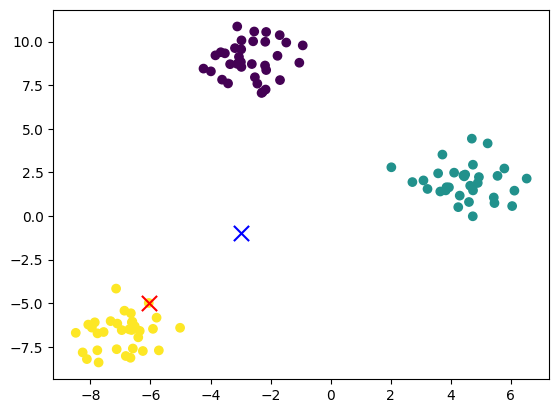

In [59]:
# n = fvecs_read('siftsmall/siftsmall_base.fvecs')
X, y = datasets.make_blobs(n_samples=100, centers=3, n_features=2, random_state=42)
# X, y = datasets.make_moons(n_samples=100, random_state=42)
search = np.array([-3.0, -1.0])

T = hkm(X, k=3, L_max=5, N_min=10)

cl, perf_obj = hkm_search(T, search)
print(cl)
print(X[cl])

plt.scatter(X[:, 0], X[:, 1], c=y)
plt.scatter(search[0], search[1], c='blue', marker='x', s=120)
plt.scatter(X[cl][0], X[cl][1], c='red', marker='x', s=120)
plt.show()

ivec files are the ground truth to test the hkm 
In addition, we provide the groundtruth for each set, in the form of the 
pre-computed k nearest neighbors and their square Euclidean distance.

The groundtruth files contain, for each query, the identifiers (vector number, starting at 0) 
of its k nearest neighbors, ordered by increasing (squared euclidean) distance. 
  • k=100 for the dataset ANN_SIFT10K, ANN_SIFT1M and ANN_GIST1M
Therefore, the first element of each integer vector is the nearest neighbor identifier 
associated with the query. 

The performance measure is recall@R, that is, for varying values of R, 
the average rate of queries for which the 1-nearest neighbor is ranked in the top R positions.
Please use this measure to allow a direct comparison of your system with most 
of the results reported in the literature.



Per testare il sistema devo fare hkm in base poi fare le query in fvecs_query poi confrontare i risultati con il groundtruth, calcolando recall@R

groudtruth sono i 100 vettori della query con i loro 100 vicini più vicini, quindi devo fare hkm sui dati di base e poi confrontare i risultati con il groundtruth, calcolando recall@R

In [60]:
def in_top_k(groundtruth_row, query_result, k):
    # groundtruth_row contains neighbors for one query, sorted by true distance.
    return query_result in groundtruth_row[:k]


def recall_at_r(groundtruth, query_results, r):
    """
    First recall definition with one relevant item per query.

    Here we evaluate if the retrieved id for each query is inside
    the first r true neighbors from the ground-truth row.
    """
    hits = sum(in_top_k(groundtruth[i], query_results[i], r) for i in range(len(query_results)))
    return hits / len(query_results)

# Testing the HKM System

In [61]:
def read_dataset(size="small"):
    """
    Reads the dataset based on the specified size.
    Parameters:
        size: "small" or "large" to specify which dataset to read.
    Returns:
        A tuple containing the base vectors, query vectors, and ground truth vectors.
    """
    if size == "small":
        return fvecs_read('siftsmall/siftsmall_base.fvecs'), fvecs_read('siftsmall/siftsmall_query.fvecs'), ivecs_read('siftsmall/siftsmall_groundtruth.ivecs')
        
    elif size == "large":
        # Read large dataset
        return fvecs_read('sift/sift_base.fvecs'), fvecs_read('sift/sift_query.fvecs'), ivecs_read('sift/sift_groundtruth.ivecs')

In [62]:
fvecs_base, fvecs_query, ivecs_groundtruth = read_dataset(size="small")

In [63]:
tree = hkm(fvecs_base, k=10, L_max=5, N_min=10)
queries_result = []
perf_objs = []
for q in fvecs_query:
    
    # start_time = time.perf_counter()
    # idx = hkm_search(tree, q, fvecs_base)
    idx, perf_obj = hkm_search(tree, q)
    # elapsed_ms = (time.perf_counter() - start_time)*1000.0

    queries_result.append(idx)
    perf_objs.append(perf_obj)

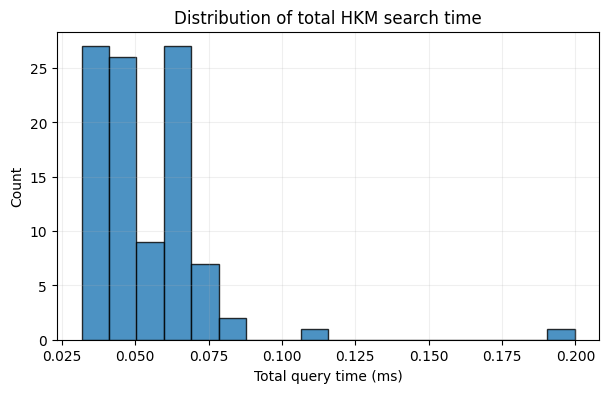

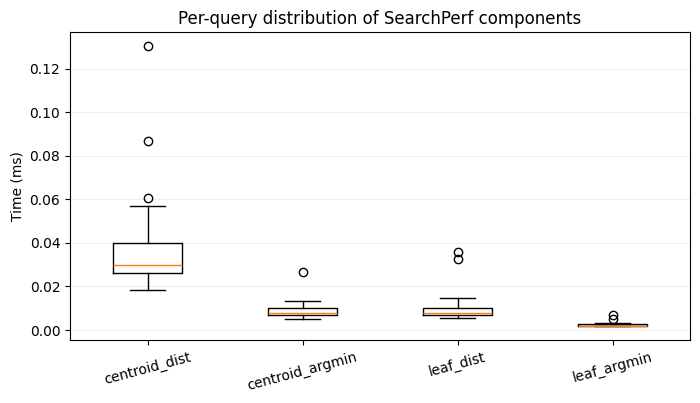

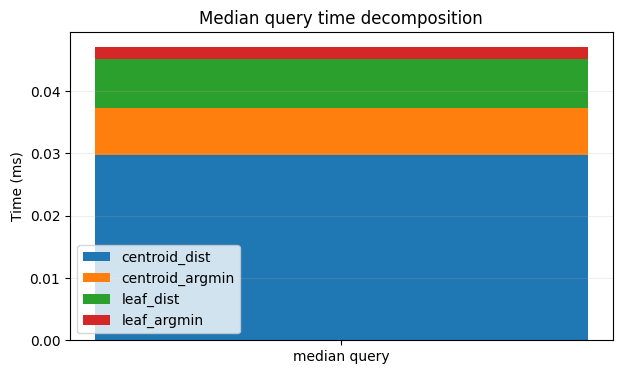

[0.033641 0.00838  0.009016 0.002261]


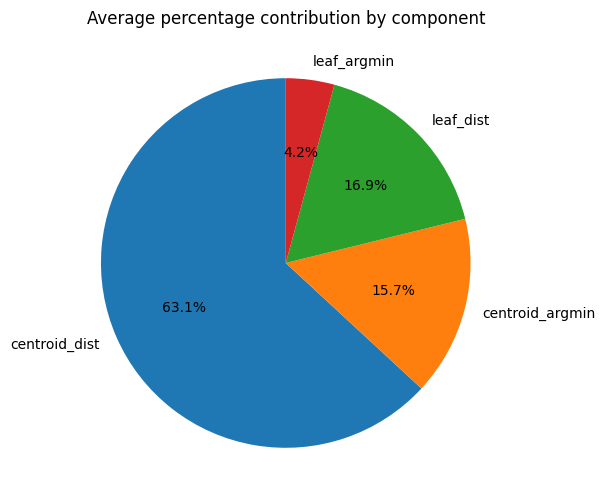

mean total:   0.0533 ms
median total: 0.0496 ms
p95 total:    0.0770 ms
centroid search iterations: 371
leaf search iterations: 100


In [64]:
# Build arrays from SearchPerf
centroid_dist = np.array([p.centroid_distances_time for p in perf_objs])
centroid_argm = np.array([p.centroid_argmin_time for p in perf_objs])
leaf_dist     = np.array([p.leaf_distances_time for p in perf_objs])
leaf_argm     = np.array([p.leaf_argmin_time for p in perf_objs])

total = centroid_dist + centroid_argm + leaf_dist + leaf_argm
labels = ["centroid_dist", "centroid_argmin", "leaf_dist", "leaf_argmin"]
parts = [centroid_dist, centroid_argm, leaf_dist, leaf_argm]

# 1) Total-time distribution
plt.figure(figsize=(7,4))
plt.hist(total, bins="fd", edgecolor="black", alpha=0.8)
plt.xlabel("Total query time (ms)")
plt.ylabel("Count")
plt.title("Distribution of total HKM search time")
plt.grid(alpha=0.2)
plt.show()

# 2) Component distributions (boxplot)
plt.figure(figsize=(8,4))
plt.boxplot(parts, tick_labels=labels, showfliers=True)
plt.ylabel("Time (ms)")
plt.title("Per-query distribution of SearchPerf components")
plt.grid(axis="y", alpha=0.2)
plt.xticks(rotation=15)
plt.show()

# 3) Median stacked breakdown
med = np.array([np.median(x) for x in parts])
plt.figure(figsize=(7,4))
bottom = 0.0
for v, name in zip(med, labels):
    plt.bar(["median query"], [v], bottom=bottom, label=name)
    bottom += v
plt.ylabel("Time (ms)")
plt.title("Median query time decomposition")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.show()

# 4) Mean percentage share
means = np.array([np.mean(x) for x in parts])
print(means)
pct_mean = 100 * means / means.sum()
plt.figure(figsize=(6,6))
plt.pie(pct_mean, labels=labels, autopct="%1.1f%%", startangle=90)
plt.title("Average percentage contribution by component")
plt.show()

print(f"mean total:   {np.mean(total):.4f} ms")
print(f"median total: {np.median(total):.4f} ms")
print(f"p95 total:    {np.percentile(total, 95):.4f} ms")
print(f"centroid search iterations: {np.sum([p.centroid_iter for p in perf_objs])}")
print(f"leaf search iterations: {len(perf_objs)}")

In [65]:
for r in [1, 5, 10, 20, 50, 100]:
    #! percentuale di quanti risultati trovati dal mio search sono presenti nei primi r risultati del groundtruth
    print(f"Recall@{r}: {recall_at_r(ivecs_groundtruth, queries_result, r):.4f}")

Recall@1: 0.3900
Recall@5: 0.6500
Recall@10: 0.7900
Recall@20: 0.9100
Recall@50: 0.9800
Recall@100: 0.9900


In [66]:
fvecs_base_l, fvecs_query_l, ivecs_groundtruth_l = read_dataset(size="large")

In [67]:
tree_n = hkm(fvecs_query_l, k=10, L_max=5, N_min=10)
queries_result_l = []
perf_objs_l = []
for q in fvecs_query_l:
    idx, perf_obj = hkm_search(tree_n, q)
    queries_result_l.append(idx)
    perf_objs_l.append(perf_obj)

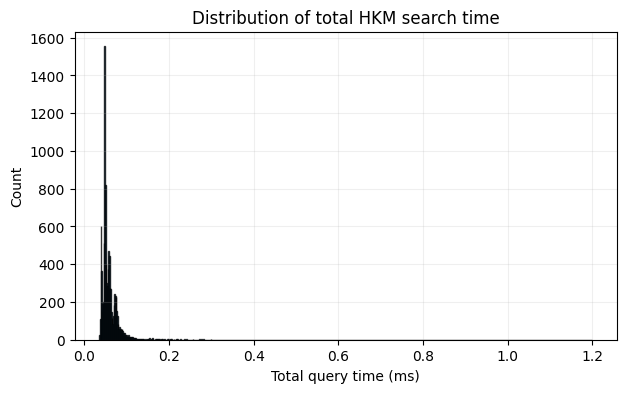

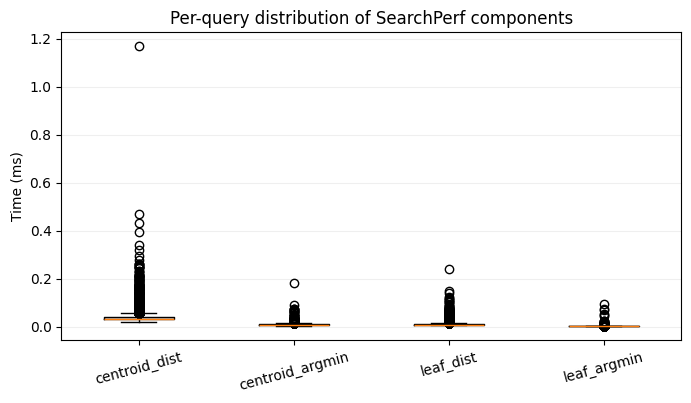

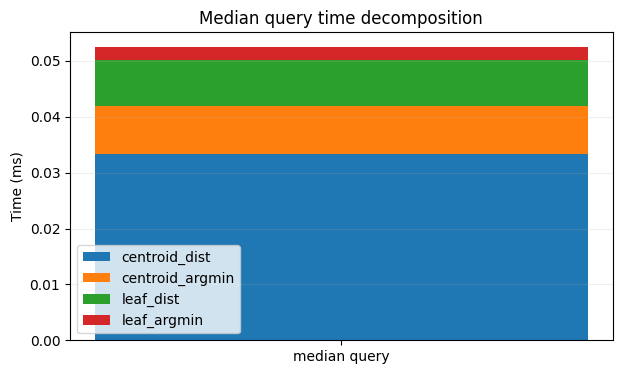

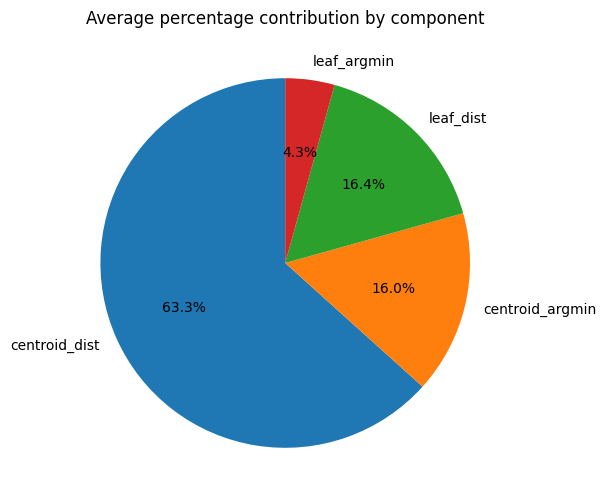

mean total:   0.0596 ms
median total: 0.0523 ms
p95 total:    0.0933 ms


In [68]:
# Build arrays from SearchPerf
centroid_dist = np.array([p.centroid_distances_time for p in perf_objs_l])
centroid_argm = np.array([p.centroid_argmin_time for p in perf_objs_l])
leaf_dist     = np.array([p.leaf_distances_time for p in perf_objs_l])
leaf_argm     = np.array([p.leaf_argmin_time for p in perf_objs_l])

total = centroid_dist + centroid_argm + leaf_dist + leaf_argm
labels = ["centroid_dist", "centroid_argmin", "leaf_dist", "leaf_argmin"]
parts = [centroid_dist, centroid_argm, leaf_dist, leaf_argm]

# 1) Total-time distribution
plt.figure(figsize=(7,4))
plt.hist(total, bins="fd", edgecolor="black", alpha=0.8)
plt.xlabel("Total query time (ms)")
plt.ylabel("Count")
plt.title("Distribution of total HKM search time")
plt.grid(alpha=0.2)
plt.show()

# 2) Component distributions (boxplot)
plt.figure(figsize=(8,4))
plt.boxplot(parts, tick_labels=labels, showfliers=True)
plt.ylabel("Time (ms)")
plt.title("Per-query distribution of SearchPerf components")
plt.grid(axis="y", alpha=0.2)
plt.xticks(rotation=15)
plt.show()

# 3) Median stacked breakdown
med = np.array([np.median(x) for x in parts])
plt.figure(figsize=(7,4))
bottom = 0.0
for v, name in zip(med, labels):
    plt.bar(["median query"], [v], bottom=bottom, label=name)
    bottom += v
plt.ylabel("Time (ms)")
plt.title("Median query time decomposition")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.show()

# 4) Mean percentage share
means = np.array([np.mean(x) for x in parts])
pct = 100 * means / means.sum()
plt.figure(figsize=(6,6))
plt.pie(pct, labels=labels, autopct="%1.1f%%", startangle=90)
plt.title("Average percentage contribution by component")
plt.show()

print(f"mean total:   {np.mean(total):.4f} ms")
print(f"median total: {np.median(total):.4f} ms")
print(f"p95 total:    {np.percentile(total, 95):.4f} ms")

test N_min from 10 to 100 steps of 5 on small dataset

In [69]:
queries_result_per_n = []
queries_time_per_n = []
for N in range(5, 10001, 10):
    try :
        tree = hkm(fvecs_base, k=5, L_max=5, N_min=N)
    except:
        print(f"Failed to build tree with N_min={N}")
        continue
    
    queries_result = []
    queries_time = []
    for q in fvecs_query:
        idx, perf_obj = hkm_search(tree, q)
        queries_result.append(idx)
        queries_time.append(perf_obj)
    
    queries_time_per_n.append(queries_time)
    queries_result_per_n.append(queries_result)

1000 1000


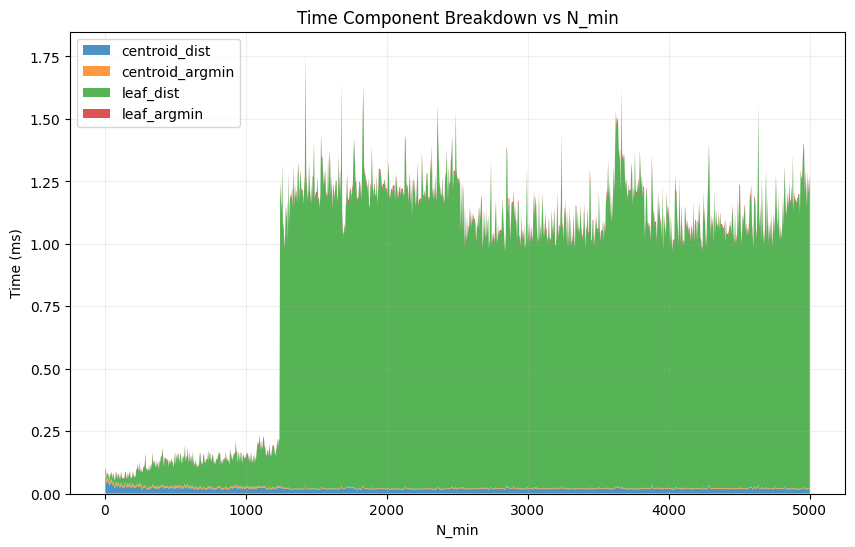

In [70]:
# asse x coerente con i risultati salvati
# caso 1: nessun fallimento nel loop originale
n_min_values_successful = list(range(5, 5 * (len(queries_time_per_n) + 1), 5))

centroid_dist_medians = [np.median([p.centroid_distances_time for p in perf_for_this_n]) for perf_for_this_n in queries_time_per_n]
centroid_argm_medians = [np.median([p.centroid_argmin_time for p in perf_for_this_n]) for perf_for_this_n in queries_time_per_n]
leaf_dist_medians     = [np.median([p.leaf_distances_time for p in perf_for_this_n]) for perf_for_this_n in queries_time_per_n]
leaf_argm_medians     = [np.median([p.leaf_argmin_time for p in perf_for_this_n]) for perf_for_this_n in queries_time_per_n]

print(len(n_min_values_successful), len(centroid_dist_medians))  # devono coincidere

plt.figure(figsize=(10, 6))
plt.stackplot(
    n_min_values_successful,
    centroid_dist_medians,
    centroid_argm_medians,
    leaf_dist_medians,
    leaf_argm_medians,
    labels=["centroid_dist", "centroid_argmin", "leaf_dist", "leaf_argmin"],
    alpha=0.8
)
plt.xlabel("N_min")
plt.ylabel("Time (ms)")
plt.title("Time Component Breakdown vs N_min")
plt.legend(loc="upper left")
plt.grid(alpha=0.2)
plt.show()

test k from 2 to 20 steps of 2 on small dataset

149 149


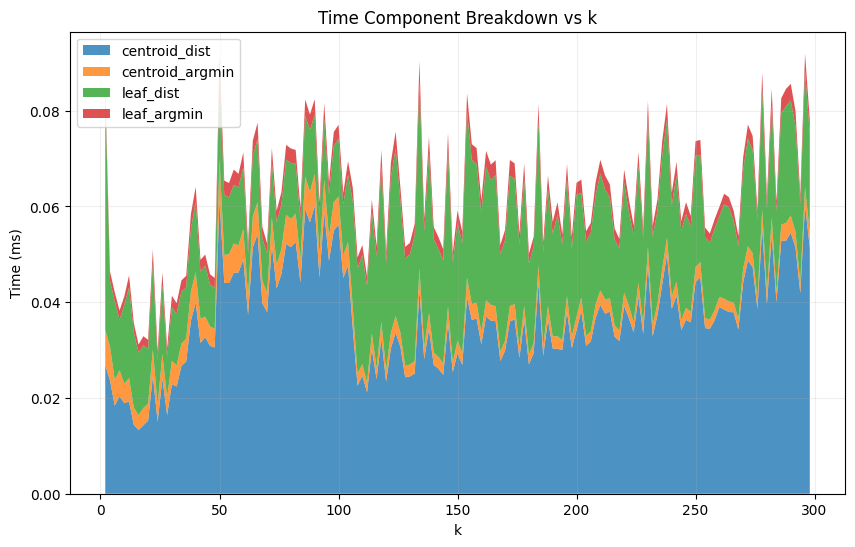

In [83]:
k_values_successful = []
queries_time_per_k = []

for k in range(2, 300, 2):
    try:
        tree = hkm(fvecs_base, k=k, L_max=5, N_min=100)
    except Exception:
        print(f"Failed to build tree with k={k}")
        continue

    perf_for_this_k = []
    for q in fvecs_query:
        _, perf_obj = hkm_search(tree, q)
        perf_for_this_k.append(perf_obj)

    k_values_successful.append(k)
    queries_time_per_k.append(perf_for_this_k)

centroid_dist_medians = [np.median([p.centroid_distances_time for p in perf]) for perf in queries_time_per_k]
centroid_argm_medians = [np.median([p.centroid_argmin_time for p in perf]) for perf in queries_time_per_k]
leaf_dist_medians     = [np.median([p.leaf_distances_time for p in perf]) for perf in queries_time_per_k]
leaf_argm_medians     = [np.median([p.leaf_argmin_time for p in perf]) for perf in queries_time_per_k]

print(len(k_values_successful), len(centroid_dist_medians))  # devono coincidere

plt.figure(figsize=(10, 6))
plt.stackplot(
    k_values_successful,
    centroid_dist_medians,
    centroid_argm_medians,
    leaf_dist_medians,
    leaf_argm_medians,
    labels=["centroid_dist", "centroid_argmin", "leaf_dist", "leaf_argmin"],
    alpha=0.8
)
plt.xlabel("k")
plt.ylabel("Time (ms)")
plt.title("Time Component Breakdown vs k")
plt.legend(loc="upper left")
plt.grid(alpha=0.2)
plt.show()

19 19


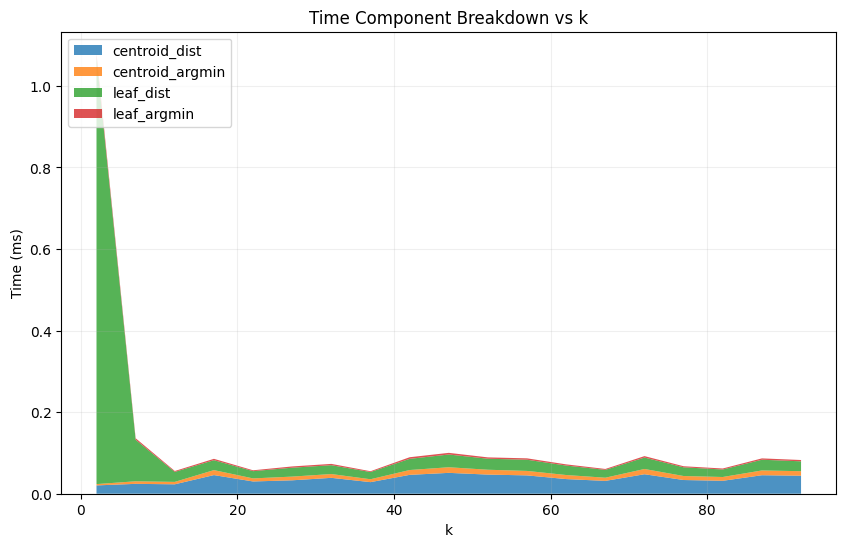

In [ ]:
# # asse x coerente con i risultati salvati
# # caso 1: nessun fallimento nel loop originale
# failed_k = {102,107,112,117,122,127,132,137,142,147,152,157,162,167,172,177,
#             182,187,192,197,202,207,212,217,222,227,232,237,242,247,252,257,
#             262,267,272,277,282,287,292,297}

# k_values_successful = [k for k in range(2, 300, 5) if k not in failed_k]
# # opzionale: allinea alla lunghezza effettiva dei dati salvati
# k_values_successful = k_values_successful[:len(queries_time_per_n)]

# centroid_dist_medians = [np.median([p.centroid_distances_time for p in perf_for_this_n]) for perf_for_this_n in queries_time_per_n]
# centroid_argm_medians = [np.median([p.centroid_argmin_time for p in perf_for_this_n]) for perf_for_this_n in queries_time_per_n]
# leaf_dist_medians     = [np.median([p.leaf_distances_time for p in perf_for_this_n]) for perf_for_this_n in queries_time_per_n]
# leaf_argm_medians     = [np.median([p.leaf_argmin_time for p in perf_for_this_n]) for perf_for_this_n in queries_time_per_n]

# print(len(k_values_successful), len(centroid_dist_medians))  # devono coincidere

# plt.figure(figsize=(10, 6))
# plt.stackplot(
#     k_values_successful,
#     centroid_dist_medians,
#     centroid_argm_medians,
#     leaf_dist_medians,
#     leaf_argm_medians,
#     labels=["centroid_dist", "centroid_argmin", "leaf_dist", "leaf_argmin"],
#     alpha=0.8
# )
# plt.xlabel("k")
# plt.ylabel("Time (ms)")
# plt.title("Time Component Breakdown vs k")
# plt.legend(loc="upper left")
# plt.grid(alpha=0.2)
# plt.show()

test L_max from 5 to 20 steps of 5 on small dataset

In [ ]:
queries_result_per_n = []
queries_time_per_n = []
for L_max in range(1, 20):
    try :
        tree = hkm(fvecs_base, k=5, L_max=L_max, N_min=10)
    except:
        print(f"Failed to build tree with L_max={L_max}")
        continue
    
    queries_result = []
    queries_time = []
    for q in fvecs_query:
        idx, perf_obj = hkm_search(tree, q)
        queries_result.append(idx)
        queries_time.append(perf_obj)
    
    queries_time_per_n.append(queries_time)
    queries_result_per_n.append(queries_result)

19 19


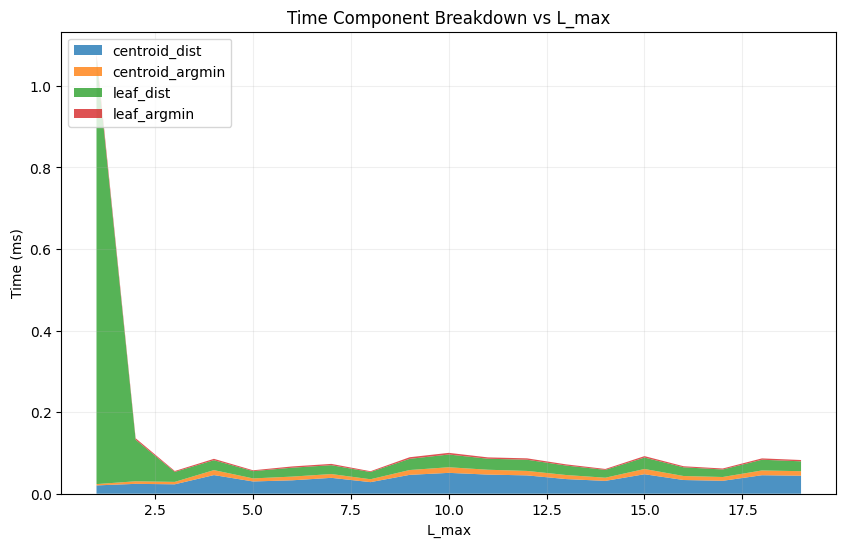

In [76]:
# asse x coerente con i risultati salvati
# caso 1: nessun fallimento nel loop originale
L_max_values_successful = list(range(1, 20))

centroid_dist_medians = [np.median([p.centroid_distances_time for p in perf_for_this_n]) for perf_for_this_n in queries_time_per_n]
centroid_argm_medians = [np.median([p.centroid_argmin_time for p in perf_for_this_n]) for perf_for_this_n in queries_time_per_n]
leaf_dist_medians     = [np.median([p.leaf_distances_time for p in perf_for_this_n]) for perf_for_this_n in queries_time_per_n]
leaf_argm_medians     = [np.median([p.leaf_argmin_time for p in perf_for_this_n]) for perf_for_this_n in queries_time_per_n]

print(len(L_max_values_successful), len(centroid_dist_medians))  # devono coincidere

plt.figure(figsize=(10, 6))
plt.stackplot(
    L_max_values_successful,
    centroid_dist_medians,
    centroid_argm_medians,
    leaf_dist_medians,
    leaf_argm_medians,
    labels=["centroid_dist", "centroid_argmin", "leaf_dist", "leaf_argmin"],
    alpha=0.8
)
plt.xlabel("L_max")
plt.ylabel("Time (ms)")
plt.title("Time Component Breakdown vs L_max")
plt.legend(loc="upper left")
plt.grid(alpha=0.2)
plt.show()

with the learn dataset ? 

# Optuna

### HKM test for best parameters

Parameters to test: 
+ k: branching factor -> k >= 2
+ L_max: maximum number of layers in the hierarchy -> L_max >= 1
+ N_min: minimum number of points in a leaf node -> N_min >= 1 , <= number of points in the dataset 

trova bound per dataset da 1M

In [24]:
from optuna.storages import RDBStorage
import optuna

storage = RDBStorage("sqlite:///db.sqlite3")

In [25]:
# for the small dataset

def objective(trial):
    k = trial.suggest_int('k', 2, 10)
    L_max = trial.suggest_int('L_max', 1, 10) # il problema è che le soluzioni preferiscono sempre L_max più basso 
    N_min = trial.suggest_int('N_min', k, 100)

    tree = hkm(fvecs_base, k=k, L_max=L_max, N_min=N_min)

    queries_result = []
    queries_time = []
    for q in fvecs_query:
        idx, perf_obj = hkm_search(tree, q)
        queries_result.append(idx)
        queries_time.append(perf_obj.total_time())

    # Compute average recall@1 across all queries
    r = 1
    avg_recall = recall_at_r(ivecs_groundtruth, queries_result, r=r) 
    median_time = np.median(queries_time)

    return avg_recall, median_time

study = optuna.create_study(directions=['maximize', 'minimize'], storage=storage, study_name="hkm_optimization_10k", load_if_exists=True)
study.set_metric_names(['recall@1', 'median_time_ms'])
study.optimize(objective, n_trials=100)

study.best_trials 

[I 2026-04-25 09:44:03,254] Using an existing study with name 'hkm_optimization_10k' instead of creating a new one.
C:\Users\Filippo Gumiero\AppData\Local\Temp\ipykernel_12372\3356320254.py:25: ExperimentalWarning: optuna.study.study.Study.set_metric_names is experimental (supported from v3.2.0). The interface can change in the future.
  study.set_metric_names(['recall@1', 'median_time_ms'])
[I 2026-04-25 09:44:04,223] Trial 101 finished with values: {'recall@1': 0.46, 'median_time_ms': 0.056150020100176334} and parameters: {'k': 6, 'L_max': 6, 'N_min': 41}.
[I 2026-04-25 09:44:05,632] Trial 102 finished with values: {'recall@1': 0.36, 'median_time_ms': 0.04164999700151384} and parameters: {'k': 7, 'L_max': 10, 'N_min': 18}.
[I 2026-04-25 09:44:07,380] Trial 103 finished with values: {'recall@1': 0.44, 'median_time_ms': 0.062449980759993196} and parameters: {'k': 6, 'L_max': 9, 'N_min': 16}.
[I 2026-04-25 09:44:08,319] Trial 104 finished with values: {'recall@1': 0.43, 'median_time_ms'

[FrozenTrial(number=2, state=<TrialState.COMPLETE: 1>, values=[0.83, 0.13374999980442226], datetime_start=datetime.datetime(2026, 4, 23, 13, 36, 12, 465221), datetime_complete=datetime.datetime(2026, 4, 23, 13, 36, 12, 652977), params={'k': 3, 'L_max': 2, 'N_min': 91}, user_attrs={}, system_attrs={'NSGAIISampler:generation': 0}, intermediate_values={}, distributions={'k': IntDistribution(high=10, log=False, low=2, step=1), 'L_max': IntDistribution(high=10, log=False, low=1, step=1), 'N_min': IntDistribution(high=100, log=False, low=3, step=1)}, trial_id=104, value=None),
 FrozenTrial(number=3, state=<TrialState.COMPLETE: 1>, values=[1.0, 1.7288499996084283], datetime_start=datetime.datetime(2026, 4, 23, 13, 36, 12, 671974), datetime_complete=datetime.datetime(2026, 4, 23, 13, 36, 12, 962926), params={'k': 2, 'L_max': 1, 'N_min': 58}, user_attrs={}, system_attrs={'NSGAIISampler:generation': 0}, intermediate_values={}, distributions={'k': IntDistribution(high=10, log=False, low=2, step=1

Fissa una recall che vogliamo raggiungere e poi trova i parametri che ci permettono di raggiungerla con il tempo più basso possibile

In [ ]:
def objective(trial):
    k = trial.suggest_int('k', 2, 10)
    L_max = trial.suggest_int('L_max', 1, 10) # il problema è che le soluzioni preferiscono sempre L_max più basso 
    N_min = trial.suggest_int('N_min', k, 100)

    tree = hkm(fvecs_base_l, k=k, L_max=L_max, N_min=N_min)

    queries_result = []
    queries_time = []
    for q in fvecs_query_l:
        idx, perf_obj = hkm_search(tree, q)
        queries_result.append(idx)
        queries_time.append(perf_obj.total_time())

    # Compute average recall@5 across all queries
    r = 5
    avg_recall = recall_at_r(ivecs_groundtruth_l, queries_result, r=r) 
    median_time = np.median(queries_time)

    return avg_recall, median_time

study = optuna.create_study(directions=['maximize', 'minimize'], storage=storage, study_name="hkm_optimization_1M", load_if_exists=True)
study.set_metric_names(['recall@5', 'median_time_ms'])
study.optimize(objective, n_trials=100)

study.best_trials 

# HNSW

In [ ]:
from hnsw import HNSW
from hnsw import Node

In [ ]:
import hnswlib

dim = fvecs_base.shape[1]
num_elements = fvecs_base.shape[0]

# Build index on base
index = hnswlib.Index(space='l2', dim=dim)
index.init_index(max_elements=num_elements, M=16, ef_construction=200)
index.set_ef(100)   # increase for better recall, decrease for speed
index.set_num_threads(-1)

ids = np.arange(num_elements)
start_build = time.perf_counter()
index.add_items(fvecs_base, ids)
build_time = time.perf_counter() - start_build

print(f"Built index in {build_time:.2f} s")

# Query on query set
k = 100
start_query = time.perf_counter()
labels, distances = index.knn_query(fvecs_query, k=k)
query_time = time.perf_counter() - start_query

print(f"Queried {len(fvecs_query)} vectors in {query_time:.2f} s")
print(f"Avg query time: {1000.0 * query_time / len(fvecs_query):.4f} ms")

# Recall@R:
# for each query, check whether the true nearest neighbor is within the top R retrieved ids
true_nn = ivecs_groundtruth[:, 0]

def recall_at_r(true_neighbors, predicted_labels, r):
    hits = np.any(predicted_labels[:, :r] == true_neighbors[:, None], axis=1)
    return hits.mean()

for r in [1, 5, 10, 20, 50, 100]:
    print(f"Recall@{r}: {recall_at_r(true_nn, labels, r):.4f}")